# Project 8: Harga Rumah Jabodetabek

Notebook ini membaca file hasil di `results/` dan menampilkan langkah analisis Q1 sampai Q14. Tidak ada angka yang diketik tangan. Sumber data: Kaggle, Versi 1, akses 23 Oktober 2026. Harga adalah harga listing.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.width', 140)
R = 'results/'
log = pd.read_csv(R + '1-data-preparation/01_cleaning_log.csv')
log

,langkah,jumlah
0,baris mentah,3553
1,setelah hapus duplikat URL,3552
2,setelah hapus duplikat ads_id,3458
3,year_built > 2026 jadi NULL,1
4,price per m2 di luar batas (flag),18
5,building_size_m2 kosong,1
6,city ada spasi di depan (di-trim),3553


## Harga per m2 per kota (Q1, Q2)

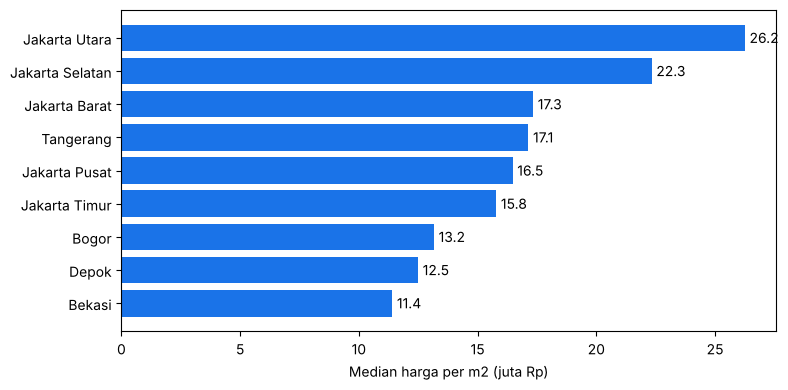

,city,n,median_ppm2
0,Jakarta Utara,123,26250000.00
1,Jakarta Selatan,226,22325387.76
2,Jakarta Barat,192,17333333.33
3,Tangerang,836,17133928.57
4,Jakarta Pusat,31,16470588.24
5,Jakarta Timur,82,15780632.41
6,Bogor,854,13158657.51
7,Depok,515,12487500.00
8,Bekasi,580,11402795.03


In [2]:
city = pd.read_csv(R + '2-analysis/02_city_summary.csv').sort_values('median_ppm2')
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(city.city, city.median_ppm2 / 1e6, color='#1A73E8')
ax.set_xlabel('Median harga per m2 (juta Rp)')
for y, v in enumerate(city.median_ppm2 / 1e6):
    ax.text(v + 0.2, y, f'{v:.1f}', va='center')
plt.tight_layout(); plt.show()
city[['city', 'n', 'median_ppm2']].sort_values('median_ppm2', ascending=False)

## Faktor harga per m2 (Q4)

In [3]:
pd.read_csv(R + '2-analysis/q4_factor_strength.csv')

,faktor,ukuran,nilai,n
0,land_size_m2,Spearman rho,0.388,3439
1,building_size_m2,Spearman rho,0.294,3439
2,bedrooms,Spearman rho,0.246,3409
3,bathrooms,Spearman rho,0.355,3414
4,carports,Spearman rho,0.204,3439
5,floors,Spearman rho,0.252,3436
6,building_age,Spearman rho,0.166,2032
7,garages,Spearman rho,0.115,3439
8,city,eta-squared,0.246,3439
9,certificate,eta-squared,0.025,3302


## Uji lima hipotesis Design

In [4]:
pd.read_csv(R + '2-analysis/02_hypothesis_tests.csv')

,hipotesis,ukuran,nilai_1,nilai_2
0,H1,Kota termahal per m2,"Jakarta Utara, Jakarta Selatan (median tertinggi)","Depok, Bekasi (median terendah)"
1,H2,Eta-squared lokasi (kota),0.246,Eta-squared jumlah kamar: 0.075
2,H3,Kecamatan dengan SHM > HGB (n>=5 kedua jenis),6 dari 11 kecamatan,-
3,H4,Spearman luas bangunan vs price per m2,0.294,-
4,H5,Proporsi listing flag (input diragukan),0.0055,Rasio ekstrem vs median kecamatan: 0.069


## Kandidat listing jauh di bawah median kecamatan (Q7)

In [5]:
cand = pd.read_csv(R + '2-analysis/02_listing_outliers_vs_district.csv')
cand[cand.ratio < 0.5].sort_values('ratio').head(10)[['city', 'district', 'address', 'price_in_rp', 'building_size_m2', 'price_per_m2', 'district_median_ppm2', 'ratio']]

,city,district,address,price_in_rp,building_size_m2,price_per_m2,district_median_ppm2,ratio
0,Bekasi,Summarecon Bekasi,"Summarecon Bekasi, Bekasi",1.250000e+08,110.0,1136363.636,1.580257e+07,0.072
1,Bekasi,Jati Asih,"Jati Asih, Bekasi",1.450000e+08,140.0,1035714.286,1.163333e+07,0.089
2,Bekasi,Bekasi Utara,"Bekasi Utara, Bekasi",4.200000e+07,40.0,1050000.000,1.040000e+07,0.101
3,Bekasi,Bekasi Kota,"Bekasi Kota, Bekasi",4.200000e+07,40.0,1050000.000,9.893939e+06,0.106
4,Depok,Cilodong,"Cilodong, Depok",7.000000e+07,45.0,1555555.556,1.169683e+07,0.133
5,Jakarta Selatan,Kebayoran Baru,"Kebayoran Baru, Jakarta Selatan",2.800000e+09,282.0,9929078.014,4.857143e+07,0.204
6,Bogor,Parung,"Parung, Bogor",7.500000e+07,30.0,2500000.000,1.165000e+07,0.215
7,Tangerang,Tangerang Kota,"Tangerang Kota, Tangerang",1.800000e+09,600.0,3000000.000,1.375496e+07,0.218
8,Bekasi,Bekasi Utara,"Bekasi Utara, Bekasi",3.200000e+08,135.0,2370370.370,1.040000e+07,0.228
9,Depok,Cinere,"Cinere, Depok",7.500000e+08,200.0,3750000.000,1.375000e+07,0.273


## Cek silang (Q14): SQL, pandas, dan spreadsheet

In [6]:
pd.concat({'sql_vs_pandas': pd.read_csv(R + '2-analysis/04_crosscheck_sql_pandas.csv'),
           'sql_vs_spreadsheet': pd.read_csv(R + '2-analysis/05_crosscheck_spreadsheet.csv')}, names=['cek'])

level  jumlah_dibandingkan  sama  selisih_maks status
cek                                                                            
sql_vs_pandas      0       kota                    9     9  0.000000e+00   PASS
                   1  kecamatan                   88    88  0.000000e+00   PASS
sql_vs_spreadsheet 0       kota                    9     9  3.352761e-08   PASS
                   1  kecamatan                   88    88  5.401671e-08   PASS

## Catatan

Batas harga per m2, minimal 10 listing per kecamatan, dan ambang rasio adalah asumsi (lihat `docs/definitions.md`). Lisensi dataset Unknown (tanpa izin penggunaan ulang yang dinyatakan).